<a href="https://colab.research.google.com/github/Eli39603/insurance-claims-ml/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Car Insurance Claim Costs
### Machine Learning final project

In this project we predict how much each driver will cost the insurance company in claims per year.

### 2. Input data

**2-a** We loaded the file from Google Drive. It has 45,000 drivers and 30 columns.

In [1]:
# 2-a Load the data
from google.colab import drive
drive.mount('/content/drive')

# All imports for the notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import norm
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, r2_score, mean_squared_error, mean_absolute_error

# Load the data
path = '/content/drive/MyDrive/פרויקט - למידת מכונה/dataset_class.csv'
dataset = pd.read_csv(path)

print(dataset.shape)
dataset.head()

Mounted at /content/drive
(45000, 30)


,customer_id_hash,agent_code,country,area_type,region_density,winter_severity,driver_age,gender,marital_status,license_years,...,annual_km_estimated,pct_intercity,pct_night_driving,parking_type,current_premium,claim_count,at_fault,days_to_settlement,police_report_filed,annual_claim_cost
0,6db089eb,A043,ES,suburban,855,1.3,75,F,widowed,54,...,7500.0,5,15,lot,4450,1,0.0,27.0,0.0,6178
1,d3a860d7,A057,GB,suburban,1225,2.7,76,M,married,45,...,3000.0,25,10,street,1630,0,NaN,NaN,NaN,0
2,f0610253,A186,IL,suburban,1651,1.9,60,M,single,42,...,12500.0,0,5,garage,980,0,NaN,NaN,NaN,0
3,3137c022,A002,JP,urban,5441,7.7,55,M,divorced,34,...,10000.0,5,5,street,1810,0,NaN,NaN,NaN,0
4,a1513621,A028,FR,urban,3231,5.9,69,M,widowed,51,...,NaN,5,40,street,12290,0,NaN,NaN,NaN,0


### 2.1 Target variable

The model predicts `annual_claim_cost`: the total cost of claims (in ILS) that the driver caused the insurance company during the policy year. If there was no claim, the value is 0. A claim is any reported event, including small damages.

### 2.2 Data Leakage Analysis

To predict `annual_claim_cost` for a **new** policy, we must remove every field that is known only **after** a claim was filed, or during the policy period.

**Fields we remove (leakage):**
* `claim_count` - information from the future (known only after the policy period starts).
* `at_fault` - known only after an accident.
* `days_to_settlement` - known only after an accident.
* `police_report_filed` - known only after an accident.
* `annual_claim_cost` - the target itself.
* `current_premium` - according to the data dictionary, this is the premium paid at the end of the policy year. It is not known when a new policy starts, so using it is leakage.

### 2.3 Data exploration

**2.3-a Column types and missing values**

Before looking at relationships in the data, we check two basic things: whether each column is stored with the right type (number or text), and how many missing values each column has. A problem in either one would break every calculation that comes after.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id_hash       45000 non-null  object 
 1   agent_code             45000 non-null  object 
 2   country                45000 non-null  object 
 3   area_type              45000 non-null  object 
 4   region_density         45000 non-null  int64  
 5   winter_severity        45000 non-null  float64
 6   driver_age             45000 non-null  int64  
 7   gender                 45000 non-null  object 
 8   marital_status         45000 non-null  object 
 9   license_years          45000 non-null  int64  
 10  prior_claims_5y        41858 non-null  float64
 11  no_claims_years        45000 non-null  int64  
 12  violations_3y          45000 non-null  int64  
 13  vehicle_type           45000 non-null  object 
 14  vehicle_age            45000 non-null  int64  
 15  en

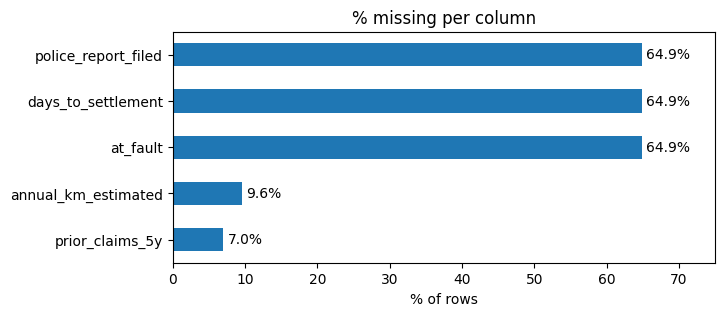

at_fault missing  False  True 
cost is 0                     
False             15793      0
True                  0  29207


In [2]:
# 2.3-a Column types and missing values
dataset.info()

missing = dataset.isna().mean() * 100
missing = missing[missing > 0].sort_values()

ax = missing.plot(kind='barh', figsize=(7, 3), title='% missing per column')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)
ax.set_xlabel('% of rows')
ax.set_xlim(0, 75)
plt.show()

# Is at_fault missing exactly for the drivers with 0 cost?
print(pd.crosstab(dataset['annual_claim_cost'] == 0,
                  dataset['at_fault'].isna(),
                  rownames=['cost is 0'], colnames=['at_fault missing']))

* `at_fault`, `police_report_filed` and `days_to_settlement` are missing in 64.9% of the rows. `at_fault` is missing for exactly the 29,207 drivers whose cost is 0, and for none of the drivers whose cost is above 0. So it is filled only when there is a claim.
* `annual_km_estimated` is missing in 9.6% of the rows, and `prior_claims_5y` in 7.0%.
* `vehicle_value` is stored as text, not as a number.

**2.3-b1 Summary statistics**

After seeing which values are missing, we check the values that do exist: the range and mean of each numeric column, to find values that make no sense.

In [3]:
# 2.3-b1 Summary statistics for the numeric columns
dataset.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
region_density,45000.0,1886.716,2161.133,4.0,498.0,1151.0,2593.0,20000.0
winter_severity,45000.0,3.459,2.215,0.0,1.7,3.3,5.0,10.0
driver_age,45000.0,48.011,16.613,18.0,35.0,47.0,60.0,90.0
license_years,45000.0,28.854,16.866,0.0,15.0,28.0,41.0,95.0
prior_claims_5y,41858.0,1.040,1.384,0.0,0.0,1.0,2.0,6.0
no_claims_years,45000.0,6.751,8.102,0.0,1.0,3.0,10.0,30.0
violations_3y,45000.0,0.416,0.717,0.0,0.0,0.0,1.0,6.0
vehicle_age,45000.0,7.639,5.313,0.0,4.0,6.0,10.0,25.0
engine_hp,45000.0,143.921,66.351,12.0,94.0,137.0,178.0,650.0
safety_features_count,45000.0,3.983,2.029,0.0,2.0,4.0,6.0,8.0


* `license_years` goes up to 95, but the oldest driver is 90.
* The maximum of `annual_km_estimated` is 999,999, a suspicious value.
* `has_telematics` also has the value 2, but according to the dictionary only 0 or 1 are allowed.

**2.3-b2 The value 999,999 in km**

In b1 we saw that the maximum of `annual_km_estimated` is 999,999. We check how many rows have it and what the next value below it is.

In [4]:
# 2.3-b2 The value 999,999 in annual_km_estimated
# annual_km_estimated: how many rows are 999,999, and what is the next highest value?
km = dataset['annual_km_estimated']
print('Rows with 999,999:', (km == 999999).sum())
print('Highest values other than 999,999:')
print(km[km != 999999].nlargest(5))

Rows with 999,999: 1386
Highest values other than 999,999:
1914     120000.0
22600    120000.0
27937    120000.0
41111    120000.0
14381    114500.0
Name: annual_km_estimated, dtype: float64


* 1,386 rows have exactly 999,999, and the next value is 120,000, with nothing in between. That is about 2,740 km per day, so it is not a real value.

**2.3-b3 License years vs. age**

In b1 we saw that `license_years` goes up to 95, but the oldest driver is 90. A license cannot be issued before about age 16, so license years cannot be greater than age minus 16. The assignment and the dictionary do not define a licensing age. We chose 16, the lowest limit among the countries in the data, so that we only flag rows that are impossible in every country. We check how many rows this happens in.

In [5]:
# 2.3-b3 license_years compared to driver_age
# license_years: in how many rows is it impossible compared to the driver's age?
too_long = dataset['license_years'] > dataset['driver_age'] - 16
print('Rows where license_years > driver_age - 16:', too_long.sum())
print(dataset.loc[too_long, ['driver_age', 'license_years']].head())

Rows where license_years > driver_age - 16: 153
     driver_age  license_years
403          30             33
468          49             56
476          33             38
645          72             78
730          46             47


* In 153 rows the license years are greater than age minus 16, and in some of them even greater than the age itself (for example, age 30 with 33 license years).

**2.3-c Why is vehicle_value stored as text?**

In 2.3-a we saw that `vehicle_value` is stored as text, even though it should be a number. Before cleaning it, we check what the problem is.

In [6]:
# 2.3-c Why is vehicle_value stored as text?
print(dataset['vehicle_value'].head(10))

as_number = pd.to_numeric(dataset['vehicle_value'], errors='coerce')
bad = dataset.loc[as_number.isna() & dataset['vehicle_value'].notna(), 'vehicle_value']
print('Values that are not numbers:', len(bad))
print(bad.value_counts().head(20))

still_bad = pd.to_numeric(bad.str.replace(',', ''), errors='coerce').isna().sum()
print('Still not numbers after removing commas:', still_bad)

0    51000
1    56500
2    19500
3    37500
4    86000
5    47000
6    29000
7    23500
8    43000
9    52000
Name: vehicle_value, dtype: object
Values that are not numbers: 682
vehicle_value
22,000    11
9,500     10
32,000     9
27,500     8
28,500     8
41,000     8
13,500     8
48,000     7
7,500      7
49,500     7
8,000      7
26,000     7
13,000     6
28,000     6
9,000      6
20,000     6
20,500     6
30,500     6
8,500      6
23,500     6
Name: count, dtype: int64
Still not numbers after removing commas: 0


* 682 values (1.5%) have a thousands comma, for example "22,000". That was enough to turn the whole column into text.
* After removing the comma, all values become numbers, so there is no other problem.

**2.3-c2 Repeated customers**

After checking the columns, we check the rows themselves. According to the assignment, each row is one driver in one policy year. If the same customer appears in several rows (several years), in cross validation they could end up in both train and test, and the model would already "know" them. That is leakage. So we check how many times each `customer_id_hash` appears.

In [7]:
# 2.3-c2 Repeated customers
ids = dataset['customer_id_hash']
print('Rows:', len(ids))
print('Unique customers:', ids.nunique())
print('How many customers appear 1, 2, 3... times:')
print(ids.value_counts().value_counts().sort_index())

Rows: 45000
Unique customers: 45000
How many customers appear 1, 2, 3... times:
count
1    45000
Name: count, dtype: int64


* Every customer appears once (45,000 out of 45,000).
* So there is no risk of the same customer being in both train and test, and a regular KFold can be used.

**2.3-d Distribution of annual_claim_cost**

This is the variable the model predicts. In 2.3-b1 we saw that its median is 0 and its maximum is 224,808, so we check how it is distributed, because this affects the choice of model and metrics.

Mean: 3051
Median: 0.0
Drivers with 0 cost: 64.9 %
Drivers above 10,000: 9.2 %


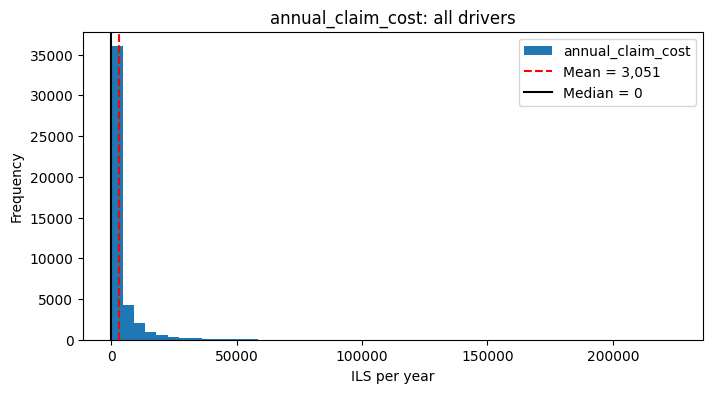

In [8]:
# 2.3-d Distribution of the target: annual_claim_cost
cost = dataset['annual_claim_cost']
print('Mean:', round(cost.mean()))
print('Median:', cost.median())
print('Drivers with 0 cost:', round((cost == 0).mean() * 100, 1), '%')
print('Drivers above 10,000:', round((cost > 10000).mean() * 100, 1), '%')

ax = cost.plot(kind='hist', bins=50, figsize=(8, 4), title='annual_claim_cost: all drivers')
ax.axvline(cost.mean(), color='red', linestyle='--', label=f'Mean = {cost.mean():,.0f}')
ax.axvline(cost.median(), color='black', label=f'Median = {cost.median():,.0f}')
ax.set_xlabel('ILS per year')
ax.legend()
plt.show()

* The mean is 3,051 ILS and the median is 0.
* 64.9% of the drivers have a cost of 0, and 9.2% cost more than 10,000 ILS.
* In the plot almost all drivers are in the first bar, near 0, with a long thin tail up to 224,808 ILS.

**2.3-e Cost of drivers with a claim**

In the previous plot almost all drivers are packed near 0, so we cannot see how the cost is spread. So we look only at drivers with a claim, on a log scale. On this scale every 10x jump in cost (for example from 1,000 to 10,000) takes the same distance on the axis, so both small and very large costs fit in the same plot.

Drivers with a claim: 15793
Mean: 8693
Median: 5359.0
Smallest cost: 600
Most common values:
annual_claim_cost
600     163
1200     37
1800     16
3512      9
1565      8
Name: count, dtype: int64


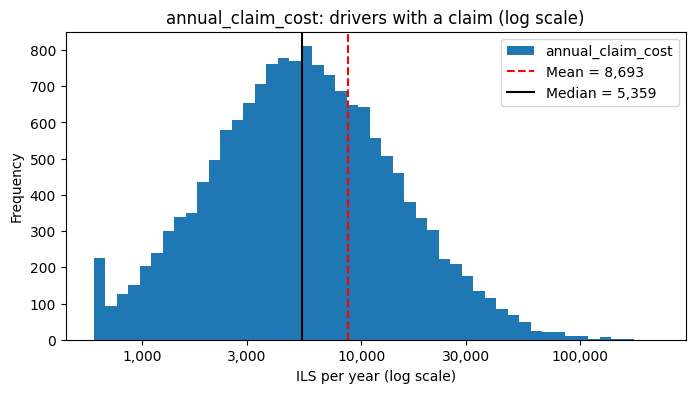

In [9]:
# 2.3-e Cost of drivers with a claim (log scale)
claims = cost[cost > 0]
print('Drivers with a claim:', len(claims))
print('Mean:', round(claims.mean()))
print('Median:', claims.median())
print('Smallest cost:', claims.min())
print('Most common values:')
print(claims.value_counts().head(5))

bins = np.logspace(np.log10(claims.min()), np.log10(claims.max()), 50)
ax = claims.plot(kind='hist', bins=bins, figsize=(8, 4),
                 title='annual_claim_cost: drivers with a claim (log scale)')
ax.set_xscale('log')
ax.set_xticks([1000, 3000, 10000, 30000, 100000])
ax.set_xticklabels(['1,000', '3,000', '10,000', '30,000', '100,000'])
ax.minorticks_off()
ax.axvline(claims.mean(), color='red', linestyle='--', label=f'Mean = {claims.mean():,.0f}')
ax.axvline(claims.median(), color='black', label=f'Median = {claims.median():,.0f}')
ax.set_xlabel('ILS per year (log scale)')
ax.legend()
plt.show()

* 15,793 drivers had a cost above 0.
* For them the mean is 8,693 ILS and the median is 5,359 ILS.
* On the log scale the plot looks like a bell.
* The lowest cost is 600 ILS, and 163 drivers have exactly 600. The next most common values are 1,200 (37 drivers) and 1,800 (16 drivers).

**2.3-f Correlation between the numeric columns**

After getting to know each column on its own, we check the relationships between them. If two features are strongly related to each other (multicollinearity), the coefficients of a linear model can "jump" and be misleading. So we check the correlation between every pair of numeric columns, and the correlation of each column with `annual_claim_cost`.

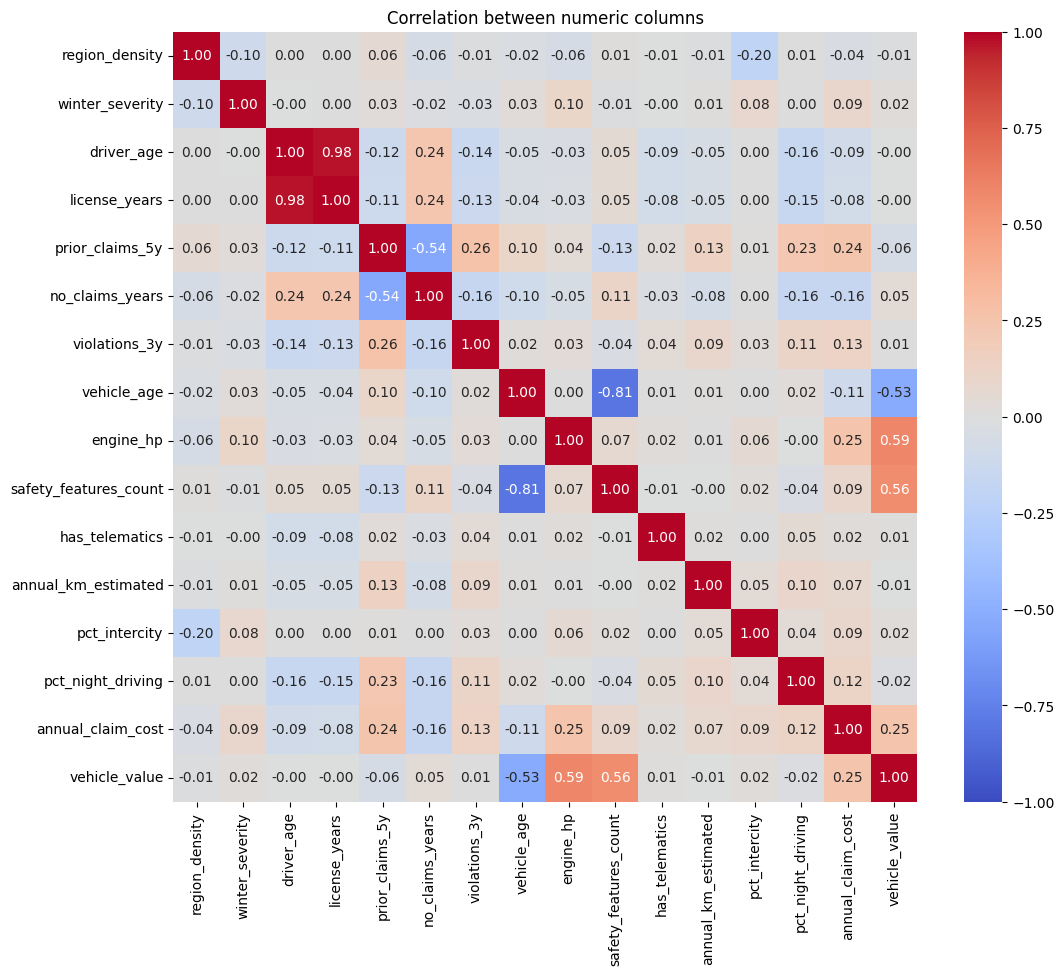

driver_age             license_years            0.976377
vehicle_age            safety_features_count   -0.806780
engine_hp              vehicle_value            0.586208
safety_features_count  vehicle_value            0.555283
prior_claims_5y        no_claims_years         -0.544507
vehicle_age            vehicle_value           -0.527655
dtype: float64
engine_hp                0.254377
vehicle_value            0.253048
prior_claims_5y          0.244234
no_claims_years         -0.162796
violations_3y            0.129079
pct_night_driving        0.120344
vehicle_age             -0.108779
pct_intercity            0.092704
safety_features_count    0.088633
winter_severity          0.087452
driver_age              -0.086270
license_years           -0.084045
annual_km_estimated      0.074249
region_density          -0.036276
has_telematics           0.022195
Name: annual_claim_cost, dtype: float64


In [10]:
# 2.3-f Correlation heatmap
# temporary copy: dataset itself is not changed
num = dataset.select_dtypes('number').copy()
num['vehicle_value'] = pd.to_numeric(dataset['vehicle_value'].str.replace(',', ''))

# leakage columns (2.2) are not used as features
leak = ['current_premium', 'claim_count', 'at_fault', 'days_to_settlement', 'police_report_filed']
num = num.drop(columns=[c for c in leak if c in num.columns])

corr = num.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric columns')
plt.show()

# strongest pairs (|r| > 0.5), without the diagonal
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False))
print(corr['annual_claim_cost'].drop('annual_claim_cost').sort_values(key=abs, ascending=False))

* 6 pairs of columns have a correlation above 0.5 (in absolute value):
* `driver_age` and `license_years` - 0.98
* `vehicle_age` and `safety_features_count` - -0.81
* `engine_hp` and `vehicle_value` - 0.59
* `safety_features_count` and `vehicle_value` - 0.56
* `prior_claims_5y` and `no_claims_years` - -0.54
* `vehicle_age` and `vehicle_value` - -0.53
* `driver_age` and `license_years` are almost identical. If both go into a linear model together, their coefficients may jump.
* The correlation of all columns with `annual_claim_cost` is weak. The highest are `engine_hp` (0.25), `vehicle_value` (0.25) and `prior_claims_5y` (0.24). For `driver_age` it is -0.09.

**2.3-f2 Spearman correlation**

The correlation in 2.3-f (Pearson) has two weaknesses:
* It only checks a straight-line relationship.
* One extreme value can change it a lot, for example 999,999 km (2.3-b2).

**Spearman** first ranks the values (smallest = 1, next = 2, and so on), and only then computes the correlation on the ranks. It checks one question: "when one column goes up, does the other go up too?"

**Example:** the values 5,000, 10,000 and 999,999 become ranks 1, 2 and 3. The 999,999 is simply "the third", not 100 times farther.

We compare the two methods against `annual_claim_cost`, and check whether the strong pairs changed.

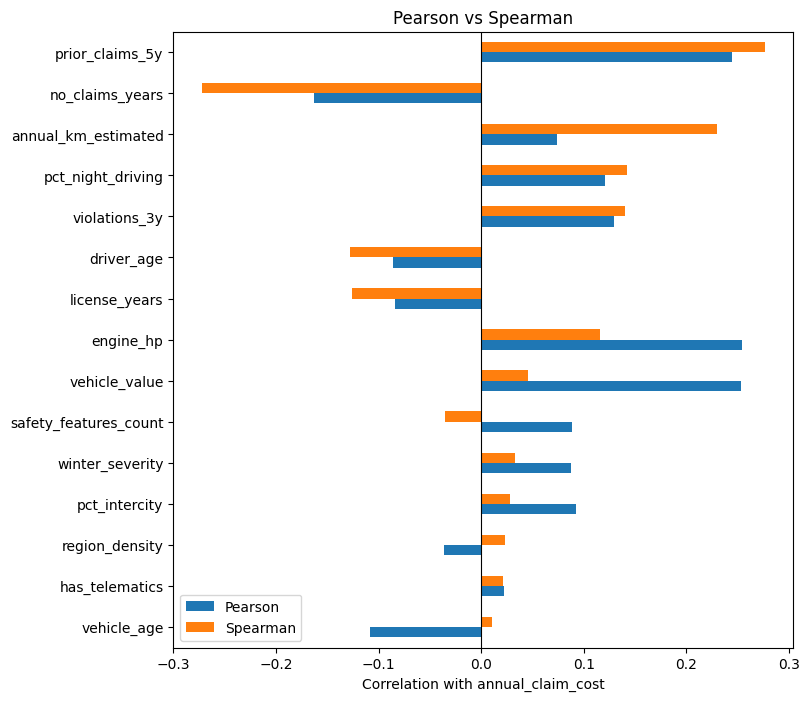

                       Pearson  Spearman
prior_claims_5y          0.244     0.277
no_claims_years         -0.163    -0.273
annual_km_estimated      0.074     0.230
pct_night_driving        0.120     0.142
violations_3y            0.129     0.140
driver_age              -0.086    -0.128
license_years           -0.084    -0.126
engine_hp                0.254     0.116
vehicle_value            0.253     0.046
safety_features_count    0.089    -0.036
winter_severity          0.087     0.033
pct_intercity            0.093     0.028
region_density          -0.036     0.023
has_telematics           0.022     0.021
vehicle_age             -0.109     0.010
driver_age             license_years            0.976832
prior_claims_5y        no_claims_years         -0.848155
vehicle_age            safety_features_count   -0.843414
                       vehicle_value           -0.720786
safety_features_count  vehicle_value            0.710638
engine_hp              vehicle_value            0.562032
dt

In [11]:
# 2.3-f2 Spearman correlation
spear = num.corr(method='spearman')

# Pearson vs Spearman, each column against the target
target = pd.DataFrame({'Pearson': corr['annual_claim_cost'],
                       'Spearman': spear['annual_claim_cost']}).drop('annual_claim_cost')
target = target.reindex(target['Spearman'].abs().sort_values().index)
target.plot(kind='barh', figsize=(8, 8))
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Correlation with annual_claim_cost')
plt.title('Pearson vs Spearman')
plt.show()
print(target.round(3).iloc[::-1])

# pairs of features with |rho| > 0.5 (compare with the 6 pairs in 2.3-f)
feat = spear.drop(index='annual_claim_cost', columns='annual_claim_cost')
pairs_s = feat.where(np.triu(np.ones(feat.shape, dtype=bool), k=1)).stack()
print(pairs_s[pairs_s.abs() > 0.5].sort_values(key=abs, ascending=False))

* The strong pairs between features are the same 6 pairs from 2.3-f. There is no new pair, but most are stronger, for example `prior_claims_5y` and `no_claims_years` -0.85 (Pearson -0.54).
* For `annual_km_estimated` the correlation with the cost rose from 0.07 to 0.23.
* For `engine_hp` and `vehicle_value` the correlation dropped (from 0.25 to 0.12, and from 0.25 to 0.05). So the Pearson relationship relied mainly on a few drivers with a very high cost.
* 64.9% of the drivers have a cost of 0, and they all get the same rank. So Spearman against the target mainly measures the relationship to having a claim at all.

**2.3-f3 Did the value 999,999 hide the km relationship?**

In f2 the correlation of `annual_km_estimated` with the cost rose from 0.07 (Pearson) to 0.23 (Spearman). This could come from the value 999,999 (2.3-b2), but also from a relationship that is not a straight line. So we replace 999,999 with a missing value, in a copy only, and compute both correlations again.

In [12]:
# 2.3-f3 Correlation sensitivity to the 999,999 mileage value
# temporary copy: dataset itself is not changed
km_original = num['annual_km_estimated']
km_clean = km_original.replace(999999, np.nan)
claim_cost = num['annual_claim_cost']

comparison = pd.DataFrame({
    'Before cleaning': [km_original.corr(claim_cost, method='pearson'),
                        km_original.corr(claim_cost, method='spearman')],
    'After cleaning': [km_clean.corr(claim_cost, method='pearson'),
                       km_clean.corr(claim_cost, method='spearman')]
}, index=['Pearson', 'Spearman'])
comparison['Difference'] = comparison['After cleaning'] - comparison['Before cleaning']
print(comparison.round(3))

          Before cleaning  After cleaning  Difference
Pearson             0.074           0.209       0.135
Spearman            0.230           0.225      -0.005


* After replacing 999,999 with a missing value, Pearson rises from 0.074 to 0.209, almost the same as Spearman.
* Spearman barely changes (0.230 → 0.225), because it ranks the values and is not affected by the size of the outlier.
* So the gap between the methods in f2 came mainly from the 999,999, and the relationship between `annual_km_estimated` and the cost also exists as a straight line.

**2.3-g Missing values in columns that go into the model**

In 2.3-a we saw missing values in two columns that can go into the model: `annual_km_estimated` (9.58%) and `prior_claims_5y` (6.98%). We check whether they are missing in the same rows.

In [13]:
# 2.3-g Missing values: are the two columns missing in the same rows?
km_miss = dataset['annual_km_estimated'].isna()
pc_miss = dataset['prior_claims_5y'].isna()
print(pd.crosstab(km_miss, pc_miss, rownames=['km missing'], colnames=['prior_claims missing']))

# if the two were unrelated: (km missing) x (prior_claims missing) / all rows
expected = km_miss.sum() * pc_miss.sum() / len(dataset)
print('Missing in both - actual:', (km_miss & pc_miss).sum())
print('Missing in both - expected if unrelated:', round(expected))

prior_claims missing  False  True 
km missing                        
False                 37867   2822
True                   3991    320
Missing in both - actual: 320
Missing in both - expected if unrelated: 301


* km is missing for 9.6% of the drivers. If the missing values are unrelated, then among the 3,142 drivers with missing prior claims, about 9.6% should also be missing km, which is about 301.
* In practice both columns are missing together in 320 rows, very close to 301. So there is no visible relationship between the missing values in the two columns.
* In the cleaning step we will need to fill both.

**2.3-h Driver age vs. cost**

After getting to know the columns and the missing values, we move to the main question of the assignment: how the cost changes with age. The assignment asks for a linear model by age for the manager. Before building it, we check how the cost changes with age, to know what a straight line can and cannot capture.

**2.3-h1 Selecting age and cost**

We take only the two columns the model needs, and check that the ages make sense and that nothing is missing.

In [14]:
# 2.3-h1 Select X and y
# Select specific columns as requested
X = dataset[['driver_age']].values
y = dataset['annual_claim_cost'].values

# Combine X and y into a single DataFrame for exploration
dataset_driver = pd.DataFrame({
    'Driver Age': X.flatten(),
    'Annual Claim Cost': y
})

dataset_driver.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Driver Age,45000.0,48.0,16.6,18.0,35.0,47.0,60.0,90.0
Annual Claim Cost,45000.0,3050.8,7551.9,0.0,0.0,0.0,3114.5,224808.0


* The age of all drivers is between 18 and 90 (mean 48), and there are 45,000 values, so nothing is missing in `driver_age`.
* The median of `annual_claim_cost` is 0, so at least half of the drivers did not file a claim.

**2.3-h2 Age vs. cost in a plot**

In h1 we saw that the ages are 18-90, and that most drivers have a cost of 0. Before fitting a line, we plot the data to see what relationship there is between age and cost. On the left, all drivers. On the right, the same data zoomed in, with lines for the mean and the median cost at each age, because 45,000 points hide each other.

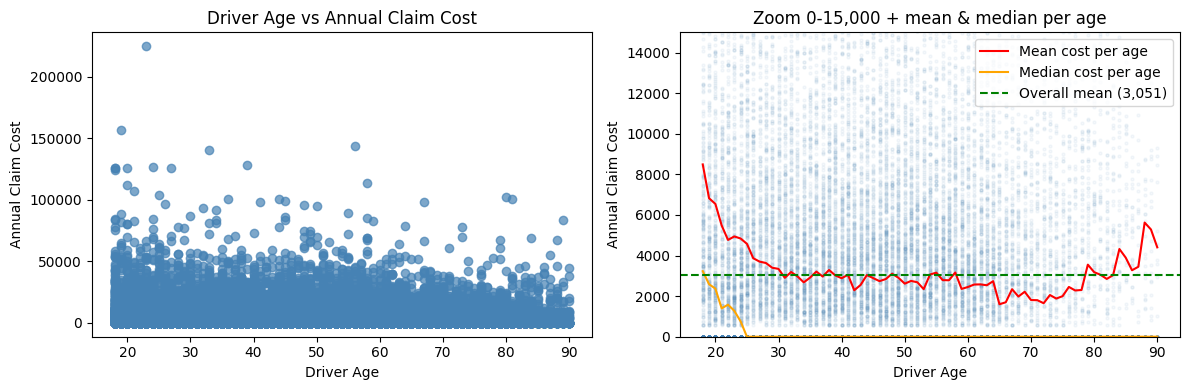

In [15]:
# 2.3-h2 Scatter plot: age vs claim cost
# Left: original scatter. Right: transparent points + mean cost per age
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X, y, color='steelblue', alpha=0.7)
axes[0].set_title('Driver Age vs Annual Claim Cost')

mean_by_age = dataset_driver.groupby('Driver Age')['Annual Claim Cost'].mean()
axes[1].scatter(X, y, color='steelblue', alpha=0.05, s=5)
axes[1].plot(mean_by_age.index, mean_by_age.values, color='red', label='Mean cost per age')
axes[1].set_title('Zoom 0-15,000 + mean & median per age')
median_by_age = dataset_driver.groupby('Driver Age')['Annual Claim Cost'].median()
axes[1].plot(median_by_age.index, median_by_age.values, color='orange', label='Median cost per age')
axes[1].axhline(y.mean(), color='green', linestyle='--', label=f'Overall mean ({y.mean():,.0f})')
axes[1].legend()
axes[1].set_ylim(0, 15000)

for ax in axes:
    ax.set_xlabel('Driver Age')
    ax.set_ylabel('Annual Claim Cost')
plt.tight_layout()
plt.show()

* In the left plot we see high costs at all ages, up to about 225,000 ILS, but no trend can be seen.
* In the right plot the mean cost drops from about 8,500 ILS at age 18 to about 2,000-3,000 ILS at ages 30-75, and rises again to about 5,600 ILS around age 88. So the relationship is U-shaped.
* The median is 0 from about age 25, so at most ages most drivers did not claim. The mean is higher because of a few expensive claims.

**2.3-h3 Chance of a claim by age**

In h2 we saw that the mean cost is U-shaped: high for young and old drivers. This mean mixes two things: how many drivers file a claim, and how much each claimant costs. Here we check the first part: the percentage of drivers with a claim in each age group. It is not clear how best to split into groups, so we compare four splits, and in each group we also show the number of drivers.

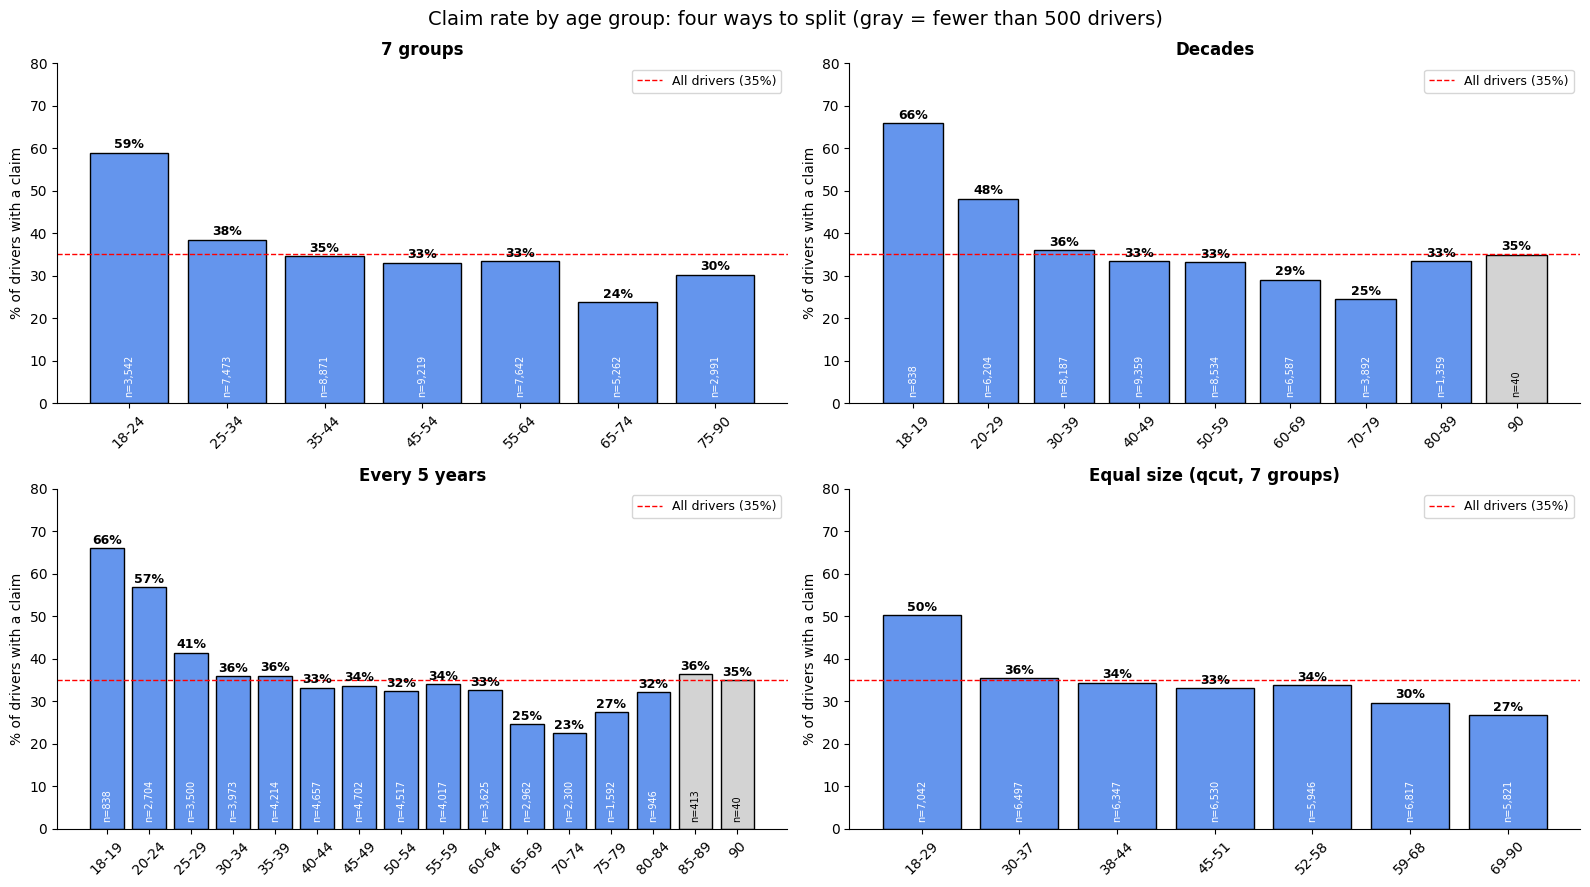

In [16]:
# 2.3-h3 Comparing ways to split ages into groups
# temporary copy: dataset itself is not changed during exploration
age_data = dataset[['driver_age', 'annual_claim_cost']].copy()
age_data['Has_Claim'] = (age_data['annual_claim_cost'] > 0).astype(int)
overall_rate = age_data['Has_Claim'].mean() * 100

splits = {
    '7 groups': pd.cut(age_data['driver_age'], bins=[15, 25, 35, 45, 55, 65, 75, 95], right=False),
    'Decades': pd.cut(age_data['driver_age'], bins=range(10, 101, 10), right=False),
    'Every 5 years': pd.cut(age_data['driver_age'], bins=range(15, 96, 5), right=False),
    'Equal size (qcut, 7 groups)': pd.qcut(age_data['driver_age'], q=7),
}

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (name, groups) in zip(axes.flatten(), splits.items()):
    summary = age_data.groupby(groups, observed=True).agg(
        rate=('Has_Claim', 'mean'), n=('Has_Claim', 'size'),
        age_min=('driver_age', 'min'), age_max=('driver_age', 'max'))
    labels = [f'{a}-{b}' if a != b else f'{a}' for a, b in zip(summary['age_min'], summary['age_max'])]
    colors = ['lightgray' if n < 500 else 'cornflowerblue' for n in summary['n']]
    bars = ax.bar(labels, summary['rate'] * 100, color=colors, edgecolor='black')
    for bar, n, col in zip(bars, summary['n'], colors):
        x = bar.get_x() + bar.get_width() / 2
        ax.text(x, bar.get_height() + 1, f'{bar.get_height():.0f}%', ha='center', fontsize=9, fontweight='bold')
        ax.text(x, 1.5, f'n={n:,}', ha='center', va='bottom', rotation=90, fontsize=7,
                color='white' if col == 'cornflowerblue' else 'black')
    ax.axhline(overall_rate, color='red', linestyle='--', linewidth=1, label=f'All drivers ({overall_rate:.0f}%)')
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_ylabel('% of drivers with a claim')
    ax.set_ylim(0, 80)
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper right', fontsize=9)
fig.suptitle('Claim rate by age group: four ways to split (gray = fewer than 500 drivers)', fontsize=14)
plt.tight_layout()
plt.show()

* In all splits the young drivers claim the most (59%-66%), compared to 35% of all drivers.
* The 5-year split shows the pattern best: a drop until about age 30, another drop at ages 65-74 (23-25%), and a rise again from age 80. In qcut this rise disappears.
* In the decade split the last group is only age 90, with 40 drivers, so its percentage is not reliable.
* So the U in the cost comes partly from young and old drivers filing more claims.

**2.3-h4 Straight line vs. U curve**

In h2 and h3 we saw that both the cost and the chance of a claim are U-shaped. So we check how much a straight line explains, compared to a curve of (age−c)², which is still a linear regression with one feature.

Straight line R^2: 0.0074
Best center: 60 | (age - 60)^2 R^2: 0.0128
Age 25 prediction: line 3,953 | U 4,563
Best possible R^2 from age alone (in-sample): 0.0188


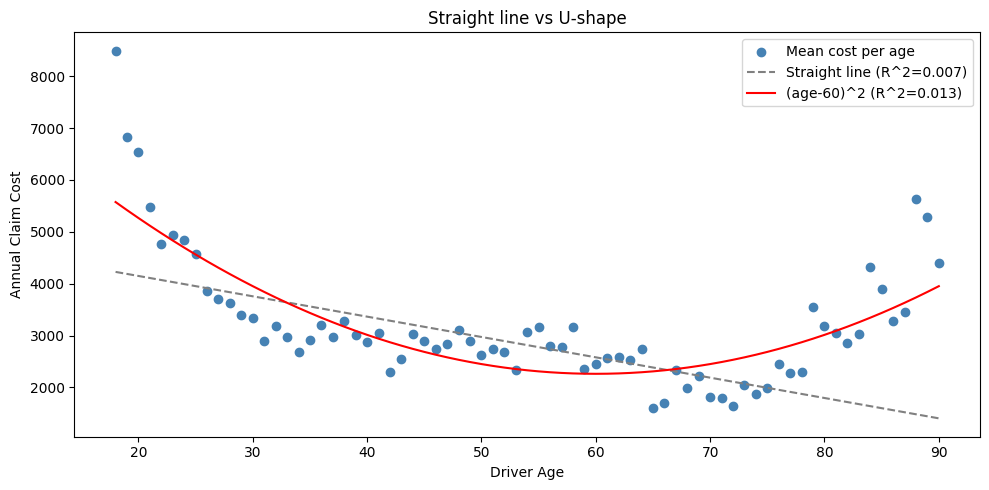

In [17]:
# 2.3-h4 Straight line vs U-shape (age - c)^2, on all drivers
ages = dataset[['driver_age']]
cost = dataset['annual_claim_cost']

line = LinearRegression().fit(ages, cost)
r2_line = line.score(ages, cost)

# try every center age and keep the one with the best R^2
results = []
for c in range(30, 76):
    feat = (ages - c) ** 2
    results.append((c, LinearRegression().fit(feat, cost).score(feat, cost)))
best_c, r2_u = max(results, key=lambda t: t[1])
u_model = LinearRegression().fit((ages - best_c) ** 2, cost)

print(f'Straight line R^2: {r2_line:.4f}')
print(f'Best center: {best_c} | (age - {best_c})^2 R^2: {r2_u:.4f}')
age_25 = pd.DataFrame({'driver_age': [25]})
print(f'Age 25 prediction: line {line.predict(age_25)[0]:,.0f} | U {u_model.predict((age_25 - best_c) ** 2)[0]:,.0f}')

# best possible R^2 from age alone: predict each driver with the mean of their age
ceiling = dataset.groupby('driver_age')['annual_claim_cost'].transform('mean')
print(f'Best possible R^2 from age alone (in-sample): {r2_score(cost, ceiling):.4f}')

# mean cost per age + both fits (ages 18-90 only)
grid = pd.DataFrame({'driver_age': np.arange(18, 91)})
mean_by_age = dataset.groupby('driver_age')['annual_claim_cost'].mean()
plt.figure(figsize=(10, 5))
plt.scatter(mean_by_age.index, mean_by_age.values, color='steelblue', label='Mean cost per age')
plt.plot(grid['driver_age'], line.predict(grid), color='gray', linestyle='--', label=f'Straight line (R^2={r2_line:.3f})')
plt.plot(grid['driver_age'], u_model.predict((grid - best_c) ** 2), color='red', label=f'(age-{best_c})^2 (R^2={r2_u:.3f})')
plt.xlabel('Driver Age')
plt.ylabel('Annual Claim Cost')
plt.title('Straight line vs U-shape')
plt.legend()
plt.tight_layout()
plt.show()

* The (age−60)² curve passes close to the means at all ages, and the straight line misses the young drivers and the drivers over 80. For example, at age 25 the line predicts 3,953 ILS, the U predicts 4,563 ILS, and the actual mean is about 4,600 ILS.
* Even the best model that can be built from age alone (the mean of each age) explains only 1.9% of the differences between drivers. The straight line explains 0.7%, and the U explains 1.3%. So no transformation of age will help much: within each age there is a very large spread.

**2.3-i Cost by gender, usage type and area**

We saw that age alone explains very little of the cost, so we check more columns. We pick the three text columns the assignment mentions explicitly: gender (`gender`), usage type (`usage_type`) and area (`area_type`). For each group we check two things: the mean cost and the percentage of drivers who filed a claim. Along the way we also check that the values in these columns are written consistently.

gender ['F', 'Female', 'M', 'Male', 'f', 'female', 'm', 'male']
usage_type ['admin_work', 'commute', 'delivery', 'leisure', 'professional']
area_type ['rural', 'suburban', 'urban']

        mean_cost  pct_claim      n
gender                             
F          2745.7       33.6  20762
M          3312.3       36.3  24238 

              mean_cost  pct_claim      n
usage_type                               
admin_work       2014.5       27.2   6226
commute          2892.3       35.6  18600
delivery         5945.5       64.5   3406
leisure          2351.5       26.9  14265
professional     6853.9       57.5   2503 

           mean_cost  pct_claim      n
area_type                             
rural         3751.3       29.7   8585
suburban      3062.5       34.4  18086
urban         2711.2       38.3  18329 



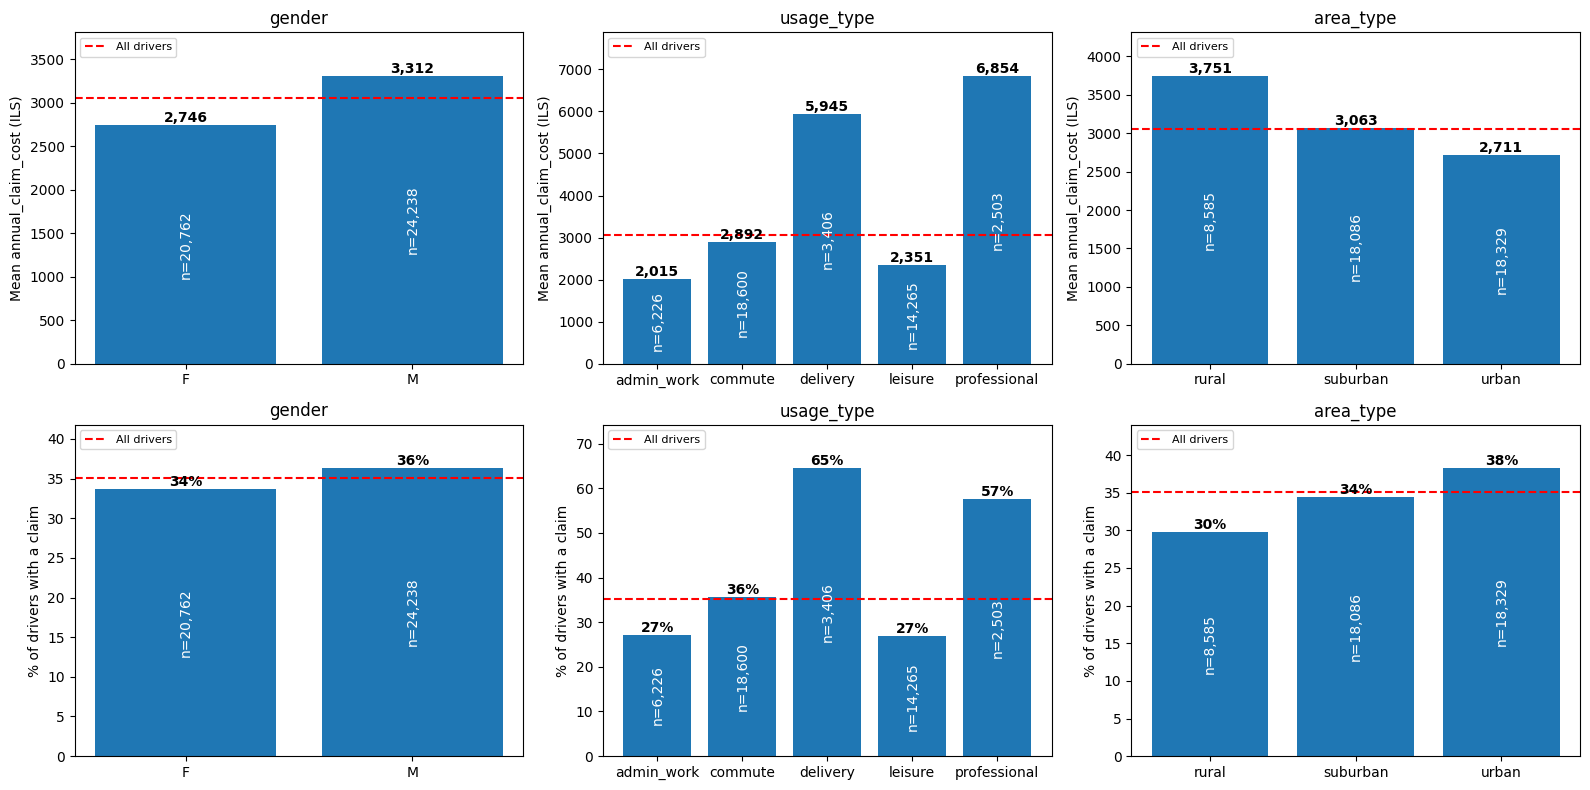

In [18]:
# 2.3-i Cost and claim rate by gender, usage_type and area_type
# spelling check: distinct values in the three columns
cat_cols = ['gender', 'usage_type', 'area_type']
for col in cat_cols:
    print(col, sorted(dataset[col].dropna().unique()))
print()

# temporary copy: gender unified to F / M only for this chart (dataset is not changed)
cats = dataset[['gender', 'usage_type', 'area_type', 'annual_claim_cost']].copy()
cats['gender'] = cats['gender'].str[0].str.upper()
cats['Has_Claim'] = (cats['annual_claim_cost'] > 0) * 100

rows = [('mean_cost', 'Mean annual_claim_cost (ILS)'),
        ('pct_claim', '% of drivers with a claim')]
overall = {'mean_cost': cats['annual_claim_cost'].mean(),
           'pct_claim': cats['Has_Claim'].mean()}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(cat_cols):
    stats = cats.groupby(col).agg(mean_cost=('annual_claim_cost', 'mean'),
                                  pct_claim=('Has_Claim', 'mean'),
                                  n=('annual_claim_cost', 'size'))
    print(stats.round(1), '\n')
    for i, (value, label) in enumerate(rows):
        ax = axes[i, j]
        bars = ax.bar(stats.index.astype(str), stats[value])
        ax.axhline(overall[value], color='red', linestyle='--', label='All drivers')
        for bar, v, n in zip(bars, stats[value], stats['n']):
            x = bar.get_x() + bar.get_width() / 2
            top = f'{v:,.0f}' if value == 'mean_cost' else f'{v:.0f}%'
            ax.text(x, v, top, ha='center', va='bottom', fontweight='bold')
            ax.text(x, v / 2, f'n={n:,}', ha='center', va='center', rotation=90, color='white')
        ax.set_ylim(0, stats[value].max() * 1.15)
        ax.set_title(col)
        ax.set_ylabel(label)
        ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

* `gender` is written in 8 different values (F, Female, f, female, and the same for M). It needs to be unified to F/M in `prepare_data`. The claim rate is almost the same (F 34%, M 36%), but men cost more on average: 3,312 ILS vs. 2,746 ILS.
* `usage_type` is the split with the biggest difference. professional and delivery cost 6,854 and 5,945 ILS on average, and 57%-65% of them claim, vs. 2,015 ILS and 27% for admin_work.
* In `area_type` the direction is reversed: rural has the fewest claimants (30%) but the highest cost (3,751 ILS), and urban has the most claimants (38%) but the lowest cost (2,711 ILS). So in rural areas claims are less common but more expensive.

**2.3-j Linear trend line by age, for the manager**

We saw that gender, usage type and area are also related to the cost, but the assignment asks to show the manager a linear regression on `driver_age` only, with a trend line for ages 0 to 100. In 2.3-h4 we saw that a U curve fits the cost better than a straight line, but that age alone explains at most 1.9%. The data has only drivers aged 18-90, so the line is solid only in this range. Below age 16 there is no license (2.3-b3), so there we manually set a cost of 0. At ages 16-17 and 91-100 the line is dotted, because there it is extrapolation, meaning a guess without data.

Intercept: 4,934 ILS (age 0 is outside the data)
Slope: -39.2 ILS per year of age
R^2 on all drivers: 0.0074
Inside the data:
driver_age
18    4228.0
30    3757.0
50    2973.0
70    2189.0
90    1404.0
dtype: float64
Manual rule (no license):
driver_age
0     0.0
15    0.0
dtype: float64
Extrapolation (no drivers at these ages):
driver_age
16     4306.0
17     4267.0
91     1365.0
100    1012.0
dtype: float64


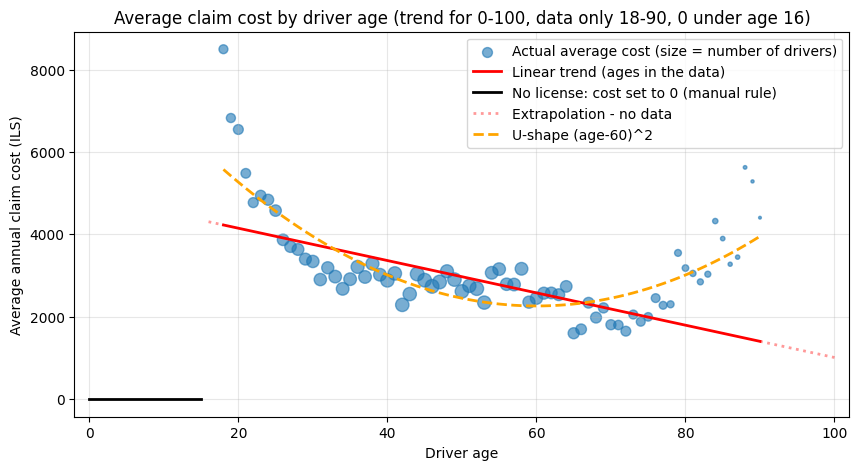

In [19]:
# 2.3-j Linear trend by age, for the manager
X_age = dataset[['driver_age']]
y_cost = dataset['annual_claim_cost']

age_model = LinearRegression()
age_model.fit(X_age, y_cost)

print(f'Intercept: {age_model.intercept_:,.0f} ILS (age 0 is outside the data)')
print(f'Slope: {age_model.coef_[0]:,.1f} ILS per year of age')
print(f'R^2 on all drivers: {age_model.score(X_age, y_cost):.4f}')

# trend line for ages 0-100 (as the assignment asks); the data has only ages 18-90
min_age, max_age = dataset['driver_age'].min(), dataset['driver_age'].max()
all_ages = pd.DataFrame({'driver_age': np.arange(0, 101)})
license_age = 16   # youngest licensing age among the countries (2.3-b3)
trend = pd.Series(age_model.predict(all_ages), index=all_ages['driver_age'])
trend.loc[:license_age - 1] = 0   # manual rule: no license under 16, so no cost
ages_in_data = all_ages[all_ages['driver_age'].between(min_age, max_age)]
print('Inside the data:'); print(trend.loc[[18, 30, 50, 70, 90]].round(0))
print('Manual rule (no license):'); print(trend.loc[[0, 15]])
print('Extrapolation (no drivers at these ages):'); print(trend.loc[[16, 17, 91, 100]].round(0))

# actual average cost and number of drivers at each age
age_stats = dataset.groupby('driver_age')['annual_claim_cost'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(age_stats.index, age_stats['mean'], s=age_stats['count'] / 10, alpha=0.6,
           label='Actual average cost (size = number of drivers)')
inside = trend.loc[min_age:max_age]
ax.plot(inside.index, inside.values, color='red', linewidth=2, label='Linear trend (ages in the data)')
ax.plot(trend.loc[:license_age - 1].index, trend.loc[:license_age - 1].values, color='black',
        linewidth=2, label='No license: cost set to 0 (manual rule)')
ax.plot(trend.loc[license_age:min_age].index, trend.loc[license_age:min_age].values, color='red', linestyle=':',
        alpha=0.4, linewidth=2, label='Extrapolation - no data')
ax.plot(trend.loc[max_age:].index, trend.loc[max_age:].values, color='red', linestyle=':',
        alpha=0.4, linewidth=2)
ax.plot(ages_in_data['driver_age'], u_model.predict((ages_in_data - best_c) ** 2),
        color='orange', linestyle='--', linewidth=2, label=f'U-shape (age-{best_c})^2')
ax.set_xlim(-2, 102)
ax.set_xlabel('Driver age')
ax.set_ylabel('Average annual claim cost (ILS)')
ax.set_title('Average claim cost by driver age (trend for 0-100, data only 18-90, 0 under age 16)')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.show()

* According to the line, each year of age lowers the mean cost by 39 ILS: an 18-year-old driver costs 4,228 ILS, and a 90-year-old costs 1,404 ILS. The R² is 0.0074.
* **The line is shown for ages 0-100, as the assignment asks, but only the 18-90 part is based on data.** At ages 0-15 the cost was manually set to 0, because there is no license. At ages 16-17 and 91-100 it is extrapolation (4,306 ILS at age 16, 1,012 ILS at age 100). The intercept (4,934 ILS at age 0) has no meaning, because there are no drivers aged 0.
* **At older ages the line goes in the wrong direction:** it keeps going down, but from age 80 the actual cost rises, up to about 5,600 ILS at age 88. The U curve fits the means better, so it is worth showing it to the manager next to the line.

### 2.4 Strategy by age group

In 2.3-j we saw that a straight line does not describe the cost of young and old drivers well. The assignment defines an expensive driver as one who costs more than 10,000 ILS a year, and asks for a strategy for at least 3 decades. We may assume that the cost at each age is normally distributed. But in 2.3-d we saw that 64.9% of the drivers have a cost of 0, so we check whether this assumption fits.

**2.4-a How to split the ages into groups**

The assignment asks for decades, but the data has only ages 18-90, so "clean" decades create small groups at the edges. We compare three splits:
* **A:** clean decades (18-19, 20-29, …, 80-89, 90).
* **B:** decades, with the edges merged (18-29, …, 80-90).
* **C:** like B, but the young are split into 18-24 and 25-29, because in 2.3-h3 we saw that the claim rate drops fast until about age 30.

In each split we check how many drivers are in each group, and whether the split hides a gap between neighboring groups.

All drivers: 9.2% expensive
A: pure decades
               n    mean  actual_pct
driver_age                          
18-19        838  7643.6        20.3
20-29       6204  4459.2        13.4
30-39       8187  3048.5         9.2
40-49       9359  2828.6         8.9
50-59       8534  2766.6         8.1
60-69       6587  2296.0         7.0
70-79       3892  2085.4         6.8
80-89       1359  3503.4        10.5
90            40  4404.2        10.0 

B: edges merged
               n    mean  actual_pct
driver_age                          
18-29       7042  4838.1        14.3
30-39       8187  3048.5         9.2
40-49       9359  2828.6         8.9
50-59       8534  2766.6         8.1
60-69       6587  2296.0         7.0
70-79       3892  2085.4         6.8
80-90       1399  3529.1        10.5 

C: young split
               n    mean  actual_pct
driver_age                          
18-24       3542  5838.5        16.9
25-29       3500  3825.7        11.6
30-39       8187  3048.5         

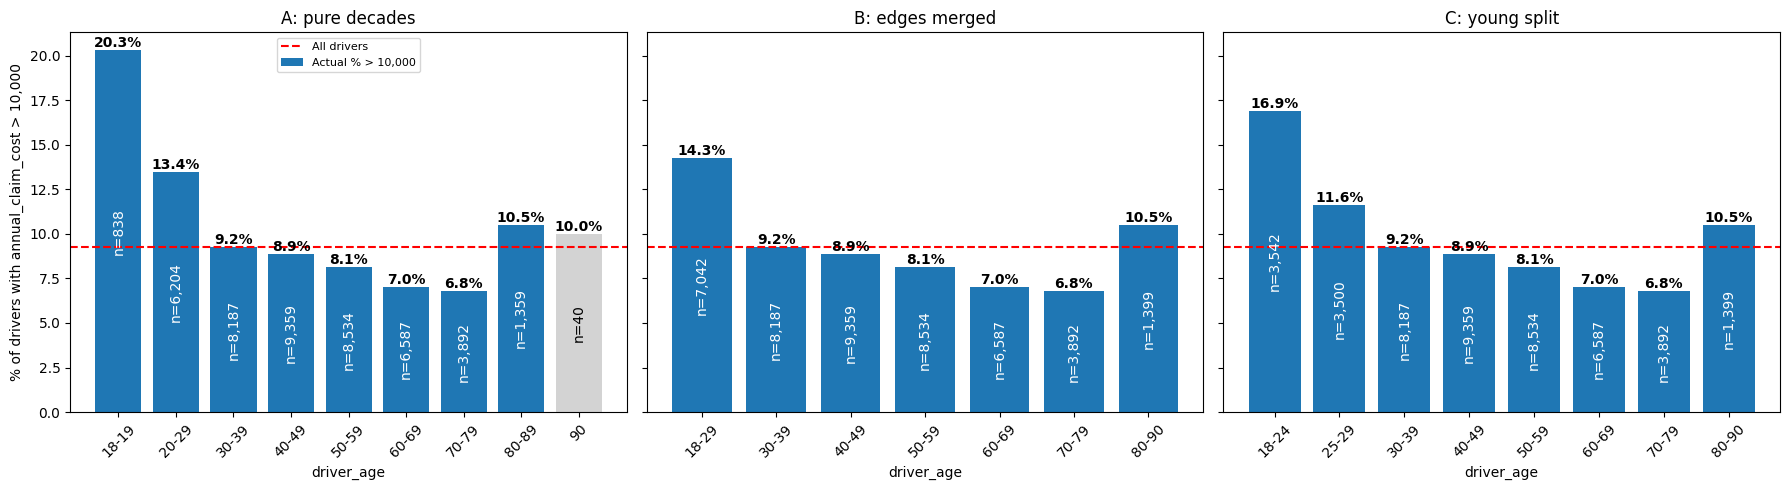

In [20]:
# 2.4-a Comparing three ways to split ages into groups
age_cost = dataset[['driver_age', 'annual_claim_cost']].copy()
age_cost['Expensive'] = (age_cost['annual_claim_cost'] > 10000) * 100
overall_pct = age_cost['Expensive'].mean()
print(f'All drivers: {overall_pct:.1f}% expensive')

options = {
    'A: pure decades': ([18, 20, 30, 40, 50, 60, 70, 80, 90, 101],
                        ['18-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90']),
    'B: edges merged': ([18, 30, 40, 50, 60, 70, 80, 101],
                        ['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-90']),
    'C: young split':  ([18, 25, 30, 40, 50, 60, 70, 80, 101],
                        ['18-24', '25-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-90']),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (name, (bins, labels)) in zip(axes, options.items()):
    group = pd.cut(age_cost['driver_age'], bins=bins, labels=labels, right=False)
    stats = age_cost.groupby(group, observed=True).agg(
        n=('annual_claim_cost', 'size'),
        mean=('annual_claim_cost', 'mean'),
        actual_pct=('Expensive', 'mean'))
    print(name); print(stats.round(1), '\n')
    colors = ['lightgray' if n < 500 else 'tab:blue' for n in stats['n']]
    bars = ax.bar(labels, stats['actual_pct'], color=colors, label='Actual % > 10,000')
    ax.axhline(overall_pct, color='red', linestyle='--', label='All drivers')
    for bar, v, n in zip(bars, stats['actual_pct'], stats['n']):
        x = bar.get_x() + bar.get_width() / 2
        ax.text(x, v, f'{v:.1f}%', ha='center', va='bottom', fontweight='bold')
        ax.text(x, v / 2, f'n={n:,}', ha='center', va='center', rotation=90,
                color='black' if n < 500 else 'white')
    ax.set_title(name)
    ax.set_xlabel('driver_age')
    ax.tick_params(axis='x', rotation=45)
axes[0].set_ylabel('% of drivers with annual_claim_cost > 10,000')
axes[0].legend(loc='upper center', fontsize=8)
plt.tight_layout()
plt.show()

* In A the edge groups are small: age 90 has only 40 drivers, and ages 18-19 have 838.
* In B the 18-29 group (14.3%) hides a gap: in C we see that ages 18-24 have 16.9% expensive drivers, and ages 25-29 have 11.6%.
* So we choose C: it has no small groups, and it shows the gap among the young. At ages 30-79 all three splits are the same.

**2.4-b Expensive drivers by age group: actual vs. the normal assumption**

In 2.4-a we chose split C. Now we check in each group what percentage of drivers actually cost more than 10,000 ILS, and compare it to what the normal assumption predicts. According to the assignment, the normal assumption is for each age separately, so for each age we compute the chance of being above 10,000 ILS from the mean and standard deviation of that age, and combine the ages into a group with a weighted average by the number of drivers.

All drivers: 9.2% expensive
              n    mean      std  actual_pct  normal_pct
Age_Group                                               
18-24      3542  5838.5  12179.1        16.9        35.4
25-29      3500  3825.7   8423.2        11.6        22.9
30-39      8187  3048.5   7313.4         9.2        16.9
40-49      9359  2828.6   6946.4         8.9        14.8
50-59      8534  2766.6   6911.6         8.1        14.4
60-69      6587  2296.0   5890.5         7.0         9.4
70-79      3892  2085.4   5683.5         6.8         7.9
80-90      1399  3529.1   8588.6        10.5        21.5


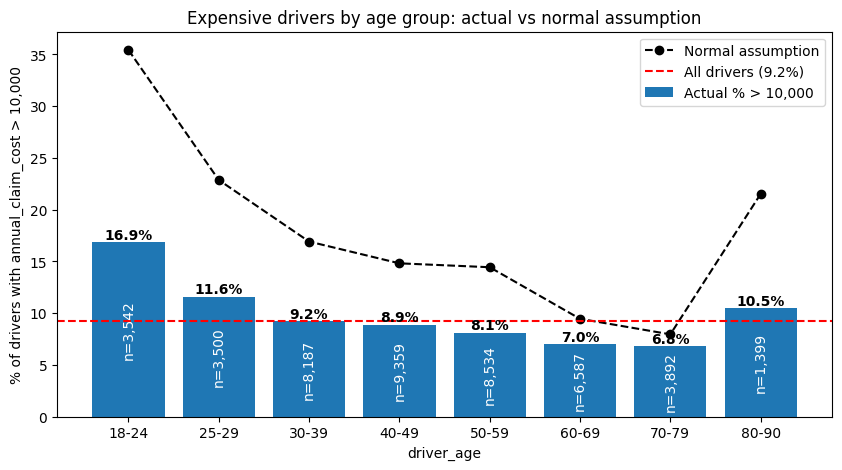

In [21]:
# 2.4-b Expensive drivers (> 10,000) per age group: actual vs normal assumption
age_cost = dataset[['driver_age', 'annual_claim_cost']].copy()
age_cost['Expensive'] = (age_cost['annual_claim_cost'] > 10000) * 100
overall_pct = age_cost['Expensive'].mean()

bins = [18, 25, 30, 40, 50, 60, 70, 80, 101]
labels = ['18-24', '25-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-90']
age_cost['Age_Group'] = pd.cut(age_cost['driver_age'], bins=bins, labels=labels, right=False)

stats = age_cost.groupby('Age_Group', observed=True).agg(
    n=('annual_claim_cost', 'size'),
    mean=('annual_claim_cost', 'mean'),
    std=('annual_claim_cost', 'std'),
    actual_pct=('Expensive', 'mean'))
# normal assumption per exact age (as the assignment states): P(cost > 10,000) with that age's mean and std
age_normal = age_cost.groupby('driver_age').agg(
    n=('annual_claim_cost', 'size'),
    mean=('annual_claim_cost', 'mean'),
    std=('annual_claim_cost', 'std'))
age_normal['expected_expensive'] = norm.sf(10000, age_normal['mean'], age_normal['std']) * age_normal['n']
age_normal['Age_Group'] = pd.cut(age_normal.index, bins=bins, labels=labels, right=False)
# weighted by the number of drivers at each age
normal_by_group = age_normal.groupby('Age_Group', observed=True)[['n', 'expected_expensive']].sum()
stats['normal_pct'] = normal_by_group['expected_expensive'] / normal_by_group['n'] * 100
print(f'All drivers: {overall_pct:.1f}% expensive')
print(stats.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, stats['actual_pct'], label='Actual % > 10,000')
ax.plot(labels, stats['normal_pct'], 'ko--', label='Normal assumption')
ax.axhline(overall_pct, color='red', linestyle='--', label=f'All drivers ({overall_pct:.1f}%)')
for bar, v, n in zip(bars, stats['actual_pct'], stats['n']):
    x = bar.get_x() + bar.get_width() / 2
    ax.text(x, v, f'{v:.1f}%', ha='center', va='bottom', fontweight='bold')
    ax.text(x, v / 2, f'n={n:,}', ha='center', va='center', rotation=90, color='white')
ax.set_xlabel('driver_age')
ax.set_ylabel('% of drivers with annual_claim_cost > 10,000')
ax.set_title('Expensive drivers by age group: actual vs normal assumption')
ax.legend()
plt.show()

* The normal assumption overestimates in all groups. For 18-24 it predicts 35.4% expensive drivers, and in practice there are 16.9%. For 80-90 it predicts 21.5%, and in practice there are 10.5%.
* The reason: the standard deviation is 2-3 times larger than the mean, because most drivers are at 0 and a few are very expensive (2.3-d). Such a distribution does not look like a bell, so the strategy will be based on the actual percentage.
* In practice, 18-24 (16.9%), 25-29 (11.6%) and 80-90 (10.5%) are above the average of all drivers (9.2%). The lowest are 60-69 and 70-79 (7.0% and 6.8%).

**2.4-c What is behind the risk in each group**

In 2.4-b we saw how many expensive drivers there are in each group, but not why. A driver can be expensive because their chance to claim is high (**claim rate**), or because when they claim, their annual cost is high (**cost per claimant**), and each case calls for a different strategy. So we split the risk into these two parts. We also check the percentage of expensive drivers at each single age, to see whether each decade is uniform inside.

           claim_rate_%  cost_per_claimant_ILS  mean_cost_ILS  \
Age_Group                                                       
18-24              59.0                 9900.0         5839.0   
25-29              41.0                 9228.0         3826.0   
30-39              36.0                 8472.0         3049.0   
40-49              33.0                 8458.0         2829.0   
50-59              33.0                 8325.0         2767.0   
60-69              29.0                 7889.0         2296.0   
70-79              25.0                 8490.0         2085.0   
80-90              33.0                10550.0         3529.0   

           vs_all_drivers_%  
Age_Group                    
18-24                  91.0  
25-29                  25.0  
30-39                  -0.0  
40-49                  -7.0  
50-59                  -9.0  
60-69                 -25.0  
70-79                 -32.0  
80-90                  16.0  


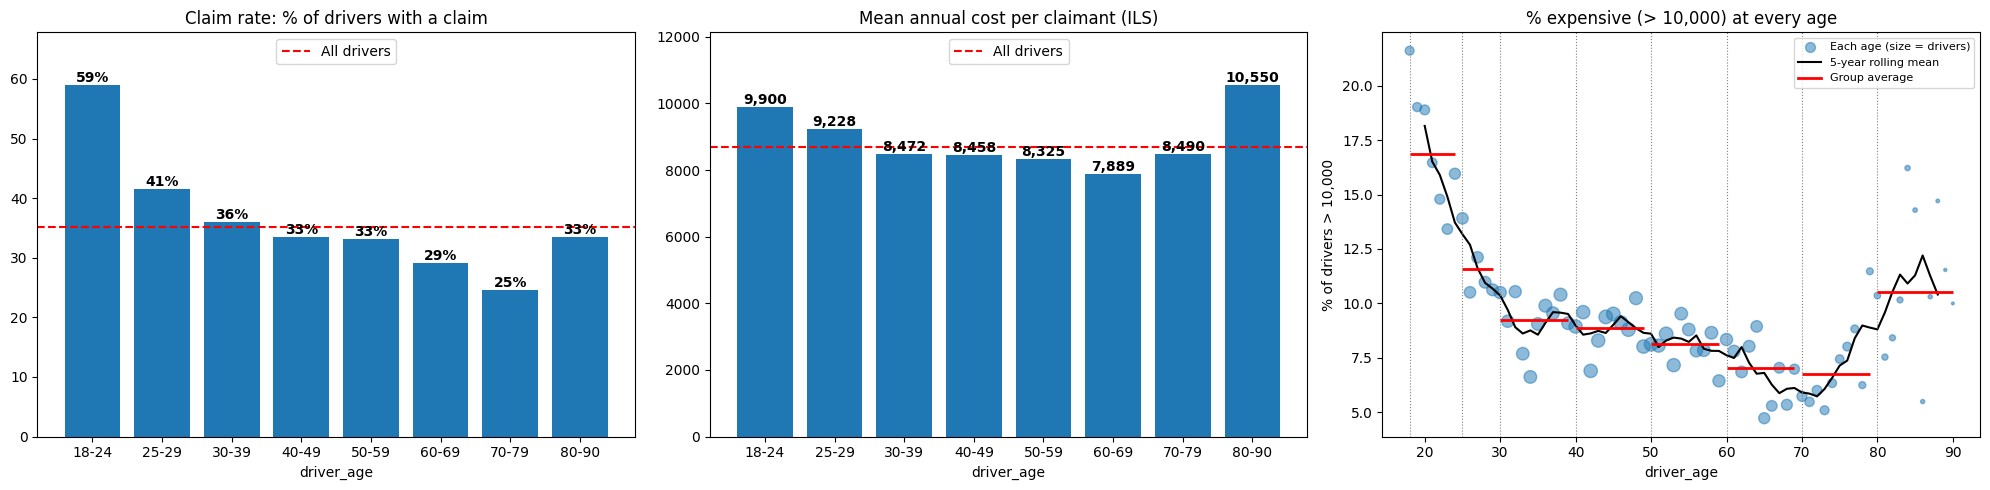

In [22]:
# 2.4-c Claim rate, cost per claimant, and every single age
age_cost['Has_Claim'] = (age_cost['annual_claim_cost'] > 0) * 100
claimants = age_cost[age_cost['annual_claim_cost'] > 0]
freq = age_cost.groupby('Age_Group', observed=True)['Has_Claim'].mean()
sev = claimants.groupby('Age_Group', observed=True)['annual_claim_cost'].mean()
# mean cost per driver (including drivers with no claim) = claim rate x cost per claimant
mean_cost = age_cost.groupby('Age_Group', observed=True)['annual_claim_cost'].mean()
print(pd.DataFrame({'claim_rate_%': freq, 'cost_per_claimant_ILS': sev, 'mean_cost_ILS': mean_cost,
                    'vs_all_drivers_%': (mean_cost / age_cost['annual_claim_cost'].mean() - 1) * 100}).round(0))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (1) claim rate and (2) cost per claimant per group
for ax, values, overall, title, fmt in [
        (axes[0], freq, age_cost['Has_Claim'].mean(), 'Claim rate: % of drivers with a claim', '{:.0f}%'),
        (axes[1], sev, claimants['annual_claim_cost'].mean(), 'Mean annual cost per claimant (ILS)', '{:,.0f}')]:
    bars = ax.bar(labels, values)
    ax.axhline(overall, color='red', linestyle='--', label='All drivers')
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt.format(v), ha='center', va='bottom', fontweight='bold')
    ax.set_ylim(0, values.max() * 1.15)
    ax.set_title(title); ax.set_xlabel('driver_age'); ax.legend(loc='upper center')

# (3) inside each group: % expensive at every single age
ax = axes[2]
per_age = age_cost.groupby('driver_age')['Expensive'].agg(['mean', 'size'])
ax.scatter(per_age.index, per_age['mean'], s=per_age['size'] / 10, alpha=0.5, label='Each age (size = drivers)')
ax.plot(per_age['mean'].rolling(5, center=True).mean(), color='black', label='5-year rolling mean')
for lo, hi, lab in zip(bins[:-1], bins[1:], labels):
    ax.hlines(stats.loc[lab, 'actual_pct'], lo, min(hi, 91) - 1, color='red', linewidth=2)
    ax.axvline(lo, color='gray', linestyle=':', linewidth=0.8)
ax.plot([], [], color='red', linewidth=2, label='Group average')
ax.set_title('% expensive (> 10,000) at every age')
ax.set_xlabel('driver_age'); ax.set_ylabel('% of drivers > 10,000'); ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

* The claim rate drops with age, from 59% at 18-24 to 25% at 70-79, and rises again to 33% at 80-90.
* The cost per claimant is similar in most groups (7,889-8,490 ILS at ages 30-79), but higher for 18-24 (9,900 ILS) and 80-90 (10,550 ILS, the highest). So the young are expensive mainly because they claim more, and the old because their cost per claimant is higher.
* Inside the decades: 30-59 are almost uniform. In 70-79 the share of expensive drivers starts at about 5% and rises to about 9% at the end of the decade, and the decade average (6.8%) hides this rise.

**2.4-d Strategy for four decades**

Based on 2.4-b and 2.4-c we chose four full decades, which show how the risk changes over a lifetime:

| Decade | Expensive | Claim rate | Cost per claimant | Cost per driver (vs. all drivers) | Strategy |
|---|---|---|---|---|---|
| 30-39 | 9.2% | 36% | 8,472 ILS | 3,049 ILS (about 0%) | **Base price.** The risk is exactly the average of all drivers. |
| 50-59 | 8.1% | 33% | 8,325 ILS | 2,767 ILS (−9%) | **Small discount.** Both the claim rate and the cost per claimant are slightly below average. |
| 70-79 | 6.8% | 25% | 8,490 ILS | 2,085 ILS (−32%) | **Discount graded by age.** The lowest claim rate, but the risk rises toward the end of the decade (from about 5% to about 9%). So the discount is large at the start of the decade and smaller at the end, and the price is updated every year. |
| 80-90 (incl. age 90) | 10.5% | 33% | 10,550 ILS | 3,529 ILS (+16%) | **Deductible or coverage cap.** They claim like the average, but their cost per claimant is the highest, so the risk is in the size of the claim, not in the number of claims. |

The riskiest group is 18-24, which is not a full decade: they claim a lot (59%), so a higher premium fits them. The strategies are a business recommendation: the data shows the level of risk, but not the exact size of the discount or surcharge.

### 3. Models: draft from the 2.2 work (needs review later)

**Note:** this code and the text below it were added as-is from the partner's notebook. They belong to section 3 and still need review and fixes before we use them.

In [23]:
# 3-a Split X and y
# Separate features and target while preventing data leakage
# use this in prepare_data func

leakage_and_id_cols = [
    'customer_id_hash',
    'claim_count',
    'at_fault',
    'days_to_settlement',
    'police_report_filed',
    'current_premium'
]

target_col = 'annual_claim_cost'

# Features (X) and Target (y)
X = dataset.drop(columns=leakage_and_id_cols + [target_col])
y = dataset[target_col]

print("Features available for training (excluding leakages):")
print(list(X.columns))
print(X)
print(y)

Features available for training (excluding leakages):
['agent_code', 'country', 'area_type', 'region_density', 'winter_severity', 'driver_age', 'gender', 'marital_status', 'license_years', 'prior_claims_5y', 'no_claims_years', 'violations_3y', 'vehicle_type', 'vehicle_age', 'engine_hp', 'vehicle_value', 'safety_features_count', 'has_telematics', 'usage_type', 'annual_km_estimated', 'pct_intercity', 'pct_night_driving', 'parking_type']
      agent_code country area_type  region_density  winter_severity  \
0           A043      ES  suburban             855              1.3   
1           A057      GB  suburban            1225              2.7   
2           A186      IL  suburban            1651              1.9   
3           A002      JP     urban            5441              7.7   
4           A028      FR     urban            3231              5.9   
...          ...     ...       ...             ...              ...   
44995       A011      ES  suburban             747              

In [24]:
# 3-b Polynomial model (draft)
# preventing Data leakage in pipeline cross validation
# (imports moved to the first cell)

# ŷ = w0 + w1x + w2x2 + … + wdxd
# w0 … wd   coefficients, learned from the data by least squares
# x, x2, …, xd   features, computed from age before fitting
# d   degree, chosen by us: a hyperparameter
# d = 1: a line    d = 2: a parabola     d = 3: a cubic


def poly_model(d):
    return make_pipeline(
        PolynomialFeatures(d, include_bias=False),
        StandardScaler(), LinearRegression())

# 1) lock away 20% as the test set
X_tv, X_test, y_tv, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)
# 2) split the rest: 75% train, 25% validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_tv, y_tv, test_size=0.25, random_state=0)

val_rmse = {}

for d in range(1, 9):
    model = poly_model(d).fit(X_tr, y_tr)
y_hat = model.predict(X_val)
val_rmse[d] = root_mean_squared_error(y_val, y_hat)
best_d = min(val_rmse, key=val_rmse.get)
print(best_d)


cv = KFold(n_splits=5, shuffle=True, random_state=0)

model = make_pipeline(
    PolynomialFeatures(d),
    StandardScaler(),
    LinearRegression()
)
cross_val_score(model, X, y, cv=cv)


ValueError: could not convert string to float: 'A013'

We use fit_transform(X_train) to compute the mean and standard deviation only from the training set, and then scale it.
We then use transform(X_test) on the test set. This ensures that no information from the test set (like its mean or range) leaks into the training phase (preventing data leakage).
* **The Pipeline .fit() on the Training Fold (No Leakage!):**
PolynomialFeatures learns the feature structure of the training fold and transforms it.
StandardScaler calculates the mean $(\mu)$ and standard deviation $(\sigma)$ strictly from this training fold only, and scales it.
LinearRegression fits its weights using this scaled training data.
* **The Pipeline .predict() / .score() on the Validation Fold:**
PolynomialFeatures transforms the validation fold.
StandardScaler transforms the validation fold using the $(\mu)$ and $(\sigma)$ calculated earlier from the training fold (it does not recalculate mean/std on the validation fold).
LinearRegression predicts the outcomes for the validation fold and calculates the score (by default, $R^2$$R^2$ score for regression).